In [3]:
import requests
import time
from datetime import date

TARGET_ID = "CHEMBL203"
BASE_URL = "https://www.ebi.ac.uk/chembl/api/data"

HEADERS = {
    "Accept": "application/json",
    "User-Agent": "mediAI-research-project/1.0"
}

def get_json_with_retry(url, params=None, retries=4):
    for attempt in range(retries):
        response = requests.get(
            url,
            params=params,
            headers=HEADERS,
            timeout=60
        )

        if response.status_code == 200:
            return response.json(), response.url

        # ChEMBL/EBI server temporary 5xx error
        if 500 <= response.status_code < 600:
            wait_time = 3 * (attempt + 1)
            print(
                f"Temporary server error: {response.status_code}. "
                f"Retrying in {wait_time} seconds..."
            )
            time.sleep(wait_time)
        else:
            response.raise_for_status()

    raise RuntimeError(
        "ChEMBL API is temporarily unavailable after retries. "
        "Wait 10 minutes and run this same cell again."
    )

# 1. Confirm the target identity
target_data, target_url = get_json_with_retry(
    f"{BASE_URL}/target/{TARGET_ID}.json"
)

# 2. Count initial raw IC50 records
params = {
    "target_chembl_id": TARGET_ID,
    "standard_type": "IC50",
    "standard_relation": "=",
    "standard_units": "nM",
    "limit": 1,
}

activity_data, activity_url = get_json_with_retry(
    f"{BASE_URL}/activity.json",
    params=params
)

print("\nmediAI Day 03 — ChEMBL source audit")
print("Date:", date.today().isoformat())
print("Target ID:", target_data["target_chembl_id"])
print("Target:", target_data["pref_name"])
print("Organism:", target_data["organism"])
print("Raw IC50 records:", activity_data["page_meta"]["total_count"])
print("Target URL:", target_url)
print("Activity query URL:", activity_url)


mediAI Day 03 — ChEMBL source audit
Date: 2026-10-14
Target ID: CHEMBL203
Target: Epidermal growth factor receptor
Organism: Homo sapiens
Raw IC50 records: 19646
Target URL: https://www.ebi.ac.uk/chembl/api/data/target/CHEMBL203.json
Activity query URL: https://www.ebi.ac.uk/chembl/api/data/activity.json?target_chembl_id=CHEMBL203&standard_type=IC50&standard_relation=%3D&standard_units=nM&limit=1


In [4]:
import pandas as pd
import time

# We fetch raw records first.
# This is NOT the curated modelling dataset yet.

params = {
    "target_chembl_id": TARGET_ID,
    "standard_type": "IC50",
    "standard_relation": "=",
    "standard_units": "nM",
    "limit": 1000,
}

first_page, first_url = get_json_with_retry(
    f"{BASE_URL}/activity.json",
    params=params
)

records = first_page["activities"]
next_path = first_page["page_meta"]["next"]
page_number = 1

print(f"Page {page_number}: {len(records)} records collected")

while next_path:
    next_url = f"https://www.ebi.ac.uk{next_path}"

    page_data, _ = get_json_with_retry(next_url)
    page_records = page_data["activities"]

    records.extend(page_records)
    next_path = page_data["page_meta"]["next"]

    page_number += 1
    print(f"Page {page_number}: {len(records)} total records")

    # Respect the public API
    time.sleep(0.2)

raw_df = pd.DataFrame(records)

keep_columns = [
    "molecule_chembl_id",
    "canonical_smiles",
    "assay_chembl_id",
    "document_chembl_id",
    "document_year",
    "assay_type",
    "target_chembl_id",
    "target_pref_name",
    "target_organism",
    "standard_type",
    "standard_relation",
    "standard_value",
    "standard_units",
    "pchembl_value",
    "potential_duplicate",
    "data_validity_comment",
]

raw_df = raw_df.reindex(columns=keep_columns)

raw_df["standard_value"] = pd.to_numeric(
    raw_df["standard_value"],
    errors="coerce"
)

output_file = "day03_egfr_raw_ic50_activity.csv"
raw_df.to_csv(output_file, index=False)

print("\n--- mediAI Day 03: Raw Dataset Audit ---")
print("Raw activity rows:", len(raw_df))
print("Unique ChEMBL molecules:", raw_df["molecule_chembl_id"].nunique())
print("Missing canonical SMILES:", raw_df["canonical_smiles"].isna().sum())
print("Missing IC50 values:", raw_df["standard_value"].isna().sum())
print("Rows with pChEMBL:", raw_df["pchembl_value"].notna().sum())
print("Potential duplicates flagged:", (raw_df["potential_duplicate"] == 1).sum())
print("Rows with data-validity comments:", raw_df["data_validity_comment"].notna().sum())
print("\nAssay types:")
print(raw_df["assay_type"].value_counts(dropna=False))
print(f"\nSaved raw file: {output_file}")

Page 1: 1000 records collected
Page 2: 2000 total records
Page 3: 3000 total records
Page 4: 4000 total records
Page 5: 5000 total records
Page 6: 6000 total records
Page 7: 7000 total records
Page 8: 8000 total records
Page 9: 9000 total records
Page 10: 10000 total records
Page 11: 11000 total records
Page 12: 12000 total records
Page 13: 13000 total records
Page 14: 14000 total records
Page 15: 15000 total records
Page 16: 16000 total records
Page 17: 17000 total records
Page 18: 18000 total records
Page 19: 19000 total records
Page 20: 19646 total records

--- mediAI Day 03: Raw Dataset Audit ---
Raw activity rows: 19646
Unique ChEMBL molecules: 10853
Missing canonical SMILES: 17
Missing IC50 values: 3
Rows with pChEMBL: 19378
Potential duplicates flagged: 2183
Rows with data-validity comments: 265

Assay types:
assay_type
B    18381
F      745
A      498
T       22
Name: count, dtype: int64

Saved raw file: day03_egfr_raw_ic50_activity.csv


In [5]:
# Day 03 — Conservative candidate dataset audit
# IMPORTANT: This is still NOT the final labelled training dataset.

candidate_df = raw_df.copy()

# Convert numeric columns safely
candidate_df["standard_value"] = pd.to_numeric(
    candidate_df["standard_value"],
    errors="coerce"
)

candidate_df["pchembl_value"] = pd.to_numeric(
    candidate_df["pchembl_value"],
    errors="coerce"
)

# Conservative record-level filters
candidate_df = candidate_df[
    (candidate_df["assay_type"] == "B") &
    (candidate_df["canonical_smiles"].notna()) &
    (candidate_df["standard_value"].notna()) &
    (candidate_df["standard_value"] > 0) &
    (candidate_df["pchembl_value"].notna()) &
    (candidate_df["potential_duplicate"] == 0) &
    (candidate_df["data_validity_comment"].isna())
].copy()

# Check repeat measurements before aggregating them
molecule_audit = (
    candidate_df
    .groupby("molecule_chembl_id")
    .agg(
        canonical_smiles=("canonical_smiles", "first"),
        n_measurements=("pchembl_value", "size"),
        median_pchembl=("pchembl_value", "median"),
        min_pchembl=("pchembl_value", "min"),
        max_pchembl=("pchembl_value", "max"),
    )
    .reset_index()
)

molecule_audit["pchembl_range"] = (
    molecule_audit["max_pchembl"] -
    molecule_audit["min_pchembl"]
)

# A range of 1 log unit is a warning flag for measurement disagreement.
# Do not remove these molecules yet; only audit them first.
molecule_audit["large_measurement_spread"] = (
    molecule_audit["pchembl_range"] >= 1.0
)

candidate_file = "day03_egfr_candidate_records_before_aggregation.csv"
audit_file = "day03_egfr_molecule_level_audit.csv"

candidate_df.to_csv(candidate_file, index=False)
molecule_audit.to_csv(audit_file, index=False)

print("--- mediAI Day 03: Conservative Candidate Audit ---")
print("Candidate activity records:", len(candidate_df))
print("Unique candidate molecules:", candidate_df["molecule_chembl_id"].nunique())
print("Repeat-measurement rows:", len(candidate_df) - candidate_df["molecule_chembl_id"].nunique())
print(
    "Molecules with >= 1.0 pChEMBL measurement spread:",
    molecule_audit["large_measurement_spread"].sum()
)

print("\nMeasurements per molecule:")
print(molecule_audit["n_measurements"].describe())

print(f"\nSaved: {candidate_file}")
print(f"Saved: {audit_file}")

--- mediAI Day 03: Conservative Candidate Audit ---
Candidate activity records: 16084
Unique candidate molecules: 10381
Repeat-measurement rows: 5703
Molecules with >= 1.0 pChEMBL measurement spread: 1397

Measurements per molecule:
count    10381.000000
mean         1.549369
std          2.018650
min          1.000000
25%          1.000000
50%          1.000000
75%          2.000000
max         89.000000
Name: n_measurements, dtype: float64

Saved: day03_egfr_candidate_records_before_aggregation.csv
Saved: day03_egfr_molecule_level_audit.csv


In [6]:
# Day 03 — Molecule-level aggregation and label-stability audit
# pChEMBL = 6.0 corresponds to IC50 = 1 micromolar (1,000 nM)

POTENCY_THRESHOLD_PCHEMBL = 6.0

molecule_level_df = molecule_audit.copy()

# One reproducible molecule-level value:
# median is less sensitive than mean to extreme measurements.
molecule_level_df["activity_label"] = (
    molecule_level_df["median_pchembl"] >= POTENCY_THRESHOLD_PCHEMBL
).astype(int)

molecule_level_df["activity_class"] = molecule_level_df[
    "activity_label"
].map({
    1: "Active (median IC50 <= 1 uM)",
    0: "Inactive (median IC50 > 1 uM)"
})

# Does the same molecule have measurements on both sides
# of the 1 uM classification threshold?
molecule_level_df["crosses_activity_threshold"] = (
    (molecule_level_df["min_pchembl"] < POTENCY_THRESHOLD_PCHEMBL) &
    (molecule_level_df["max_pchembl"] >= POTENCY_THRESHOLD_PCHEMBL)
)

# Main baseline candidate:
# remove only molecules whose repeated measurements would
# produce conflicting active/inactive labels.
stable_label_df = molecule_level_df[
    ~molecule_level_df["crosses_activity_threshold"]
].copy()

all_molecule_file = "day03_egfr_molecule_level_median_all.csv"
stable_file = "day03_egfr_stable_label_candidates.csv"

molecule_level_df.to_csv(all_molecule_file, index=False)
stable_label_df.to_csv(stable_file, index=False)

print("--- mediAI Day 03: Label-Stability Audit ---")
print("Threshold:", POTENCY_THRESHOLD_PCHEMBL, "pChEMBL (IC50 <= 1 uM)")
print("All molecule-level rows:", len(molecule_level_df))
print(
    "Molecules crossing the activity threshold:",
    molecule_level_df["crosses_activity_threshold"].sum()
)
print("Stable-label candidate molecules:", len(stable_label_df))

print("\nAll molecule-level class distribution:")
print(molecule_level_df["activity_class"].value_counts())

print("\nStable-label class distribution:")
print(stable_label_df["activity_class"].value_counts())

print("\nStable-label class percentages:")
print(
    (stable_label_df["activity_class"]
     .value_counts(normalize=True)
     .mul(100)
     .round(2))
)

print(f"\nSaved: {all_molecule_file}")
print(f"Saved: {stable_file}")

--- mediAI Day 03: Label-Stability Audit ---
Threshold: 6.0 pChEMBL (IC50 <= 1 uM)
All molecule-level rows: 10381
Molecules crossing the activity threshold: 539
Stable-label candidate molecules: 9842

All molecule-level class distribution:
activity_class
Active (median IC50 <= 1 uM)     7884
Inactive (median IC50 > 1 uM)    2497
Name: count, dtype: int64

Stable-label class distribution:
activity_class
Active (median IC50 <= 1 uM)     7511
Inactive (median IC50 > 1 uM)    2331
Name: count, dtype: int64

Stable-label class percentages:
activity_class
Active (median IC50 <= 1 uM)     76.32
Inactive (median IC50 > 1 uM)    23.68
Name: proportion, dtype: float64

Saved: day03_egfr_molecule_level_median_all.csv
Saved: day03_egfr_stable_label_candidates.csv


In [7]:
# Install RDKit if this Colab runtime does not already have it
%pip install -q rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 50.6 MB/s eta 0:00:00


In [8]:
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize
import pandas as pd

# Start from the stable molecule-level labels
structure_df = stable_label_df.copy()

uncharger = rdMolStandardize.Uncharger()

def standardize_smiles(smiles):
    """
    Convert a ChEMBL canonical SMILES into a reproducible,
    RDKit-valid parent/neutralized representation.
    """
    try:
        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            return None

        # Keep the main parent fragment if salts/fragments exist
        parent_mol = rdMolStandardize.FragmentParent(mol)

        # Neutralize where RDKit can do so safely
        neutral_mol = uncharger.uncharge(parent_mol)

        return Chem.MolToSmiles(neutral_mol, canonical=True)

    except Exception:
        return None

structure_df["standardized_smiles"] = structure_df[
    "canonical_smiles"
].apply(standardize_smiles)

# Remove invalid or unparseable molecules
valid_structure_df = structure_df[
    structure_df["standardized_smiles"].notna()
].copy()

# Check whether the same standardized structure has conflicting labels
structure_label_counts = (
    valid_structure_df
    .groupby("standardized_smiles")["activity_label"]
    .nunique()
)

conflicting_structures = structure_label_counts[
    structure_label_counts > 1
].index

# Exclude only truly conflicting structure-label cases
no_conflict_df = valid_structure_df[
    ~valid_structure_df["standardized_smiles"].isin(conflicting_structures)
].copy()

# Keep one reproducible representative row per standardized structure
model_candidate_df = (
    no_conflict_df
    .sort_values(
        ["standardized_smiles", "n_measurements"],
        ascending=[True, False]
    )
    .drop_duplicates(
        subset="standardized_smiles",
        keep="first"
    )
    .copy()
)

audit_file = "day03_egfr_rdkit_structure_audit.csv"
model_candidate_file = "day03_egfr_model_ready_candidate.csv"

valid_structure_df.to_csv(audit_file, index=False)
model_candidate_df.to_csv(model_candidate_file, index=False)

print("--- mediAI Day 03: RDKit Structure Audit ---")
print("Stable-label input molecules:", len(stable_label_df))
print(
    "Invalid/unparseable SMILES removed:",
    len(structure_df) - len(valid_structure_df)
)
print(
    "Unique standardized structures:",
    valid_structure_df["standardized_smiles"].nunique()
)
print(
    "Conflicting structure-label cases excluded:",
    len(conflicting_structures)
)
print(
    "Final model-ready unique structures:",
    len(model_candidate_df)
)

print("\nFinal model-candidate class distribution:")
print(model_candidate_df["activity_class"].value_counts())

print("\nFinal model-candidate class percentages:")
print(
    model_candidate_df["activity_class"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(f"\nSaved: {audit_file}")
print(f"Saved: {model_candidate_file}")

Streaming output truncated to the last 5000 lines.
[14:22:20] Running Normalizer
[14:22:20] Running LargestFragmentChooser
[14:22:20] Running Uncharger
[14:22:20] Initializing MetalDisconnector
[14:22:20] Running MetalDisconnector
[14:22:20] Initializing Normalizer
[14:22:20] Running Normalizer
[14:22:20] Running LargestFragmentChooser
[14:22:20] Running Uncharger
[14:22:20] Initializing MetalDisconnector
[14:22:20] Running MetalDisconnector
[14:22:20] Initializing Normalizer
[14:22:20] Running Normalizer
[14:22:20] Running LargestFragmentChooser
[14:22:20] Running Uncharger
[14:22:20] Initializing MetalDisconnector
[14:22:20] Running MetalDisconnector
[14:22:20] Initializing Normalizer
[14:22:20] Running Normalizer
[14:22:20] Running LargestFragmentChooser
[14:22:20] Running Uncharger
[14:22:20] Initializing MetalDisconnector
[14:22:20] Running MetalDisconnector
[14:22:20] Initializing Normalizer
[14:22:20] Running Normalizer
[14:22:20] Running LargestFragmentChooser
[14:22:20] Runnin

--- mediAI Day 03: RDKit Structure Audit ---
Stable-label input molecules: 9842
Invalid/unparseable SMILES removed: 0
Unique standardized structures: 9806
Conflicting structure-label cases excluded: 0
Final model-ready unique structures: 9806

Final model-candidate class distribution:
activity_class
Active (median IC50 <= 1 uM)     7484
Inactive (median IC50 > 1 uM)    2322
Name: count, dtype: int64

Final model-candidate class percentages:
activity_class
Active (median IC50 <= 1 uM)     76.32
Inactive (median IC50 > 1 uM)    23.68
Name: proportion, dtype: float64

Saved: day03_egfr_rdkit_structure_audit.csv
Saved: day03_egfr_model_ready_candidate.csv


[14:22:21] Running Uncharger
[14:22:21] Initializing MetalDisconnector
[14:22:21] Running MetalDisconnector
[14:22:21] Initializing Normalizer
[14:22:21] Running Normalizer
[14:22:21] Running LargestFragmentChooser
[14:22:21] Running Uncharger
[14:22:21] Initializing MetalDisconnector
[14:22:21] Running MetalDisconnector
[14:22:21] Initializing Normalizer
[14:22:21] Running Normalizer
[14:22:21] Running LargestFragmentChooser
[14:22:21] Running Uncharger
[14:22:21] Initializing MetalDisconnector
[14:22:21] Running MetalDisconnector
[14:22:21] Initializing Normalizer
[14:22:21] Running Normalizer
[14:22:21] Running LargestFragmentChooser
[14:22:21] Running Uncharger
[14:22:21] Initializing MetalDisconnector
[14:22:21] Running MetalDisconnector
[14:22:21] Initializing Normalizer
[14:22:21] Running Normalizer
[14:22:21] Running LargestFragmentChooser
[14:22:21] Running Uncharger
[14:22:21] Initializing MetalDisconnector
[14:22:21] Running MetalDisconnector
[14:22:21] Initializing Normaliz

In [9]:
# Day 03 — Assay-confidence audit
# We inspect assay metadata BEFORE deciding the final modelling dataset.

import pandas as pd
import time

assay_ids = (
    candidate_df["assay_chembl_id"]
    .dropna()
    .unique()
    .tolist()
)

print("Unique assays to audit:", len(assay_ids))

# Query the ChEMBL API in small batches.
# Batching avoids an unnecessarily long API URL.
batch_size = 100
assay_records = []

for start in range(0, len(assay_ids), batch_size):
    batch = assay_ids[start:start + batch_size]

    params = {
        "assay_chembl_id__in": ",".join(batch),
        "limit": 1000,
    }

    batch_data, _ = get_json_with_retry(
        f"{BASE_URL}/assay.json",
        params=params
    )

    assay_records.extend(batch_data["assays"])

    completed = min(start + batch_size, len(assay_ids))
    print(f"Assay metadata collected: {completed}/{len(assay_ids)}")

    time.sleep(0.2)

assay_metadata_df = pd.DataFrame(assay_records)

assay_keep_columns = [
    "assay_chembl_id",
    "assay_type",
    "confidence_score",
    "confidence_description",
    "relationship_type",
    "relationship_description",
    "bao_label",
    "target_chembl_id",
]

assay_metadata_df = assay_metadata_df.reindex(
    columns=assay_keep_columns
)

candidate_with_assay_df = candidate_df.merge(
    assay_metadata_df,
    on="assay_chembl_id",
    how="left",
    suffixes=("_activity", "_assay")
)

assay_file = "day03_egfr_assay_metadata.csv"
candidate_assay_file = (
    "day03_egfr_candidate_records_with_assay_metadata.csv"
)

assay_metadata_df.to_csv(assay_file, index=False)
candidate_with_assay_df.to_csv(candidate_assay_file, index=False)

print("\n--- mediAI Day 03: Assay-Confidence Audit ---")

print("\nAssay-level confidence score distribution:")
print(
    assay_metadata_df["confidence_score"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nActivity-record confidence score distribution:")
print(
    candidate_with_assay_df["confidence_score"]
    .value_counts(dropna=False)
    .sort_index()
)

print("\nRelationship types:")
print(
    assay_metadata_df["relationship_type"]
    .value_counts(dropna=False)
)

print(
    "\nRecords missing assay confidence metadata:",
    candidate_with_assay_df["confidence_score"].isna().sum()
)

print(f"\nSaved: {assay_file}")
print(f"Saved: {candidate_assay_file}")

Unique assays to audit: 1717
Assay metadata collected: 100/1717
Assay metadata collected: 200/1717
Assay metadata collected: 300/1717
Assay metadata collected: 400/1717
Assay metadata collected: 500/1717
Assay metadata collected: 600/1717
Assay metadata collected: 700/1717
Assay metadata collected: 800/1717
Assay metadata collected: 900/1717
Assay metadata collected: 1000/1717
Assay metadata collected: 1100/1717
Assay metadata collected: 1200/1717
Assay metadata collected: 1300/1717
Assay metadata collected: 1400/1717
Assay metadata collected: 1500/1717
Assay metadata collected: 1600/1717
Assay metadata collected: 1700/1717
Assay metadata collected: 1717/1717

--- mediAI Day 03: Assay-Confidence Audit ---

Assay-level confidence score distribution:
confidence_score
8     308
9    1409
Name: count, dtype: int64

Activity-record confidence score distribution:
confidence_score
8     4014
9    12070
Name: count, dtype: int64

Relationship types:
relationship_type
D    1409
H     308
Name: 

In [10]:
from rdkit import Chem, RDLogger
from rdkit.Chem.MolStandardize import rdMolStandardize
import pandas as pd

# Hide repetitive RDKit standardization messages
RDLogger.DisableLog("rdApp.*")

POTENCY_THRESHOLD_PCHEMBL = 6.0

# 1. Keep only direct, high-confidence EGFR evidence
primary_records_df = candidate_with_assay_df[
    (candidate_with_assay_df["confidence_score"] == 9) &
    (candidate_with_assay_df["relationship_type"] == "D")
].copy()

# 2. Aggregate repeated measurements molecule by molecule
primary_molecule_df = (
    primary_records_df
    .groupby("molecule_chembl_id")
    .agg(
        canonical_smiles=("canonical_smiles", "first"),
        n_measurements=("pchembl_value", "size"),
        median_pchembl=("pchembl_value", "median"),
        min_pchembl=("pchembl_value", "min"),
        max_pchembl=("pchembl_value", "max"),
    )
    .reset_index()
)

primary_molecule_df["pchembl_range"] = (
    primary_molecule_df["max_pchembl"] -
    primary_molecule_df["min_pchembl"]
)

# 3. Exclude molecules where repeat measurements cross
# the predeclared 1 micromolar activity threshold
primary_molecule_df["crosses_activity_threshold"] = (
    (primary_molecule_df["min_pchembl"] < POTENCY_THRESHOLD_PCHEMBL) &
    (primary_molecule_df["max_pchembl"] >= POTENCY_THRESHOLD_PCHEMBL)
)

primary_stable_df = primary_molecule_df[
    ~primary_molecule_df["crosses_activity_threshold"]
].copy()

# 4. RDKit structure standardization
uncharger = rdMolStandardize.Uncharger()

def standardize_smiles_primary(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles)

        if mol is None:
            return None

        parent_mol = rdMolStandardize.FragmentParent(mol)
        neutral_mol = uncharger.uncharge(parent_mol)

        return Chem.MolToSmiles(
            neutral_mol,
            canonical=True
        )

    except Exception:
        return None

primary_stable_df["standardized_smiles"] = primary_stable_df[
    "canonical_smiles"
].apply(standardize_smiles_primary)

primary_stable_df = primary_stable_df[
    primary_stable_df["standardized_smiles"].notna()
].copy()

# 5. Create active / inactive labels
primary_stable_df["activity_label"] = (
    primary_stable_df["median_pchembl"] >= POTENCY_THRESHOLD_PCHEMBL
).astype(int)

primary_stable_df["activity_class"] = primary_stable_df[
    "activity_label"
].map({
    1: "Active (median IC50 <= 1 uM)",
    0: "Inactive (median IC50 > 1 uM)"
})

# 6. Check duplicate standardized structures with conflicting labels
structure_label_counts = (
    primary_stable_df
    .groupby("standardized_smiles")["activity_label"]
    .nunique()
)

conflicting_structures = structure_label_counts[
    structure_label_counts > 1
].index

primary_model_df = primary_stable_df[
    ~primary_stable_df["standardized_smiles"].isin(
        conflicting_structures
    )
].copy()

# Keep one reproducible row for each standardized structure
primary_model_df = (
    primary_model_df
    .sort_values(
        ["standardized_smiles", "n_measurements"],
        ascending=[True, False]
    )
    .drop_duplicates(
        subset="standardized_smiles",
        keep="first"
    )
    .copy()
)

records_file = "day03_egfr_primary_high_confidence_records.csv"
dataset_file = "day03_egfr_primary_model_candidate.csv"

primary_records_df.to_csv(records_file, index=False)
primary_model_df.to_csv(dataset_file, index=False)

print("--- mediAI Day 03: Primary High-Confidence Dataset ---")
print("High-confidence raw records:", len(primary_records_df))
print(
    "High-confidence unique molecules:",
    primary_molecule_df["molecule_chembl_id"].nunique()
)
print(
    "Molecules crossing activity threshold:",
    primary_molecule_df["crosses_activity_threshold"].sum()
)
print(
    "Conflicting standardized structures removed:",
    len(conflicting_structures)
)
print(
    "Final primary model-candidate structures:",
    len(primary_model_df)
)

print("\nPrimary dataset class distribution:")
print(primary_model_df["activity_class"].value_counts())

print("\nPrimary dataset class percentages:")
print(
    primary_model_df["activity_class"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(f"\nSaved: {records_file}")
print(f"Saved: {dataset_file}")

--- mediAI Day 03: Primary High-Confidence Dataset ---
High-confidence raw records: 12070
High-confidence unique molecules: 8106
Molecules crossing activity threshold: 320
Conflicting standardized structures removed: 0
Final primary model-candidate structures: 7757

Primary dataset class distribution:
activity_class
Active (median IC50 <= 1 uM)     6242
Inactive (median IC50 > 1 uM)    1515
Name: count, dtype: int64

Primary dataset class percentages:
activity_class
Active (median IC50 <= 1 uM)     80.47
Inactive (median IC50 > 1 uM)    19.53
Name: proportion, dtype: float64

Saved: day03_egfr_primary_high_confidence_records.csv
Saved: day03_egfr_primary_model_candidate.csv


In [11]:
from rdkit import Chem, DataStructs
from rdkit.Chem import AllChem
from rdkit.Chem.Scaffolds import MurckoScaffold

from sklearn.model_selection import (
    train_test_split,
    GroupShuffleSplit
)

import numpy as np
import pandas as pd

# Start only from the frozen primary high-confidence dataset
model_df = primary_model_df.copy().reset_index(drop=True)

FP_RADIUS = 2
FP_SIZE = 2048
TEST_SIZE = 0.20
RANDOM_SEED = 42

# -------------------------------------------------------
# 1. Build Morgan fingerprints
# -------------------------------------------------------

morgan_generator = AllChem.GetMorganGenerator(
    radius=FP_RADIUS,
    fpSize=FP_SIZE
)

fingerprint_rows = []

for smiles in model_df["standardized_smiles"]:
    mol = Chem.MolFromSmiles(smiles)

    fp = morgan_generator.GetFingerprint(mol)

    fp_array = np.zeros((FP_SIZE,), dtype=np.uint8)
    DataStructs.ConvertToNumpyArray(fp, fp_array)

    fingerprint_rows.append(fp_array)

X = np.asarray(fingerprint_rows, dtype=np.uint8)
y = model_df["activity_label"].to_numpy(dtype=int)

# -------------------------------------------------------
# 2. Generate Bemis–Murcko scaffolds
# -------------------------------------------------------

def get_murcko_scaffold(smiles, molecule_id):
    mol = Chem.MolFromSmiles(smiles)

    scaffold = MurckoScaffold.MurckoScaffoldSmiles(mol=mol)

    # Acyclic molecules do not have a Murcko ring scaffold.
    # Give each one a unique group instead of creating one
    # giant empty-scaffold group.
    if not scaffold:
        scaffold = f"ACYCLIC_{molecule_id}"

    return scaffold

model_df["murcko_scaffold"] = [
    get_murcko_scaffold(smiles, molecule_id)
    for smiles, molecule_id in zip(
        model_df["standardized_smiles"],
        model_df["molecule_chembl_id"]
    )
]

# -------------------------------------------------------
# 3. Random stratified split
# -------------------------------------------------------

all_indices = np.arange(len(model_df))

random_train_idx, random_test_idx = train_test_split(
    all_indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED,
    stratify=y
)

model_df["random_split"] = "train"
model_df.loc[random_test_idx, "random_split"] = "test"

# -------------------------------------------------------
# 4. Scaffold split
# -------------------------------------------------------

scaffold_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=RANDOM_SEED
)

scaffold_train_idx, scaffold_test_idx = next(
    scaffold_splitter.split(
        X,
        y,
        groups=model_df["murcko_scaffold"]
    )
)

model_df["scaffold_split"] = "train"
model_df.loc[scaffold_test_idx, "scaffold_split"] = "test"

# -------------------------------------------------------
# 5. Save reproducible artefacts
# -------------------------------------------------------

np.savez_compressed(
    "day03_egfr_morgan_fingerprints.npz",
    X=X,
    y=y
)

split_columns = [
    "molecule_chembl_id",
    "standardized_smiles",
    "median_pchembl",
    "activity_label",
    "activity_class",
    "murcko_scaffold",
    "random_split",
    "scaffold_split",
]

model_df[split_columns].to_csv(
    "day03_egfr_split_assignments.csv",
    index=False
)

# -------------------------------------------------------
# 6. Audit output
# -------------------------------------------------------

def class_summary(dataframe, split_column):
    return (
        pd.crosstab(
            dataframe[split_column],
            dataframe["activity_class"],
            normalize="index"
        )
        .mul(100)
        .round(2)
    )

print("--- mediAI Day 03: Fingerprint + Split Audit ---")
print("Fingerprint matrix shape:", X.shape)
print("Morgan fingerprint settings:")
print(f"Radius = {FP_RADIUS}, fpSize = {FP_SIZE}")

print("\nUnique Murcko scaffolds:",
      model_df["murcko_scaffold"].nunique())

print(
    "Acyclic structures:",
    model_df["murcko_scaffold"]
    .str.startswith("ACYCLIC_")
    .sum()
)

print("\nRandom split sizes:")
print(model_df["random_split"].value_counts())

print("\nRandom split class percentages:")
print(class_summary(model_df, "random_split"))

print("\nScaffold split sizes:")
print(model_df["scaffold_split"].value_counts())

print("\nScaffold split class percentages:")
print(class_summary(model_df, "scaffold_split"))

print("\nSaved: day03_egfr_morgan_fingerprints.npz")
print("Saved: day03_egfr_split_assignments.csv")

--- mediAI Day 03: Fingerprint + Split Audit ---
Fingerprint matrix shape: (7757, 2048)
Morgan fingerprint settings:
Radius = 2, fpSize = 2048

Unique Murcko scaffolds: 2924
Acyclic structures: 1

Random split sizes:
random_split
train    6205
test     1552
Name: count, dtype: int64

Random split class percentages:
activity_class  Active (median IC50 <= 1 uM)  Inactive (median IC50 > 1 uM)
random_split                                                               
test                                   80.48                          19.52
train                                  80.47                          19.53

Scaffold split sizes:
scaffold_split
train    6339
test     1418
Name: count, dtype: int64

Scaffold split class percentages:
activity_class  Active (median IC50 <= 1 uM)  Inactive (median IC50 > 1 uM)
scaffold_split                                                             
test                                   80.18                          19.82
train                   

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    matthews_corrcoef,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss
)

import pandas as pd
import numpy as np

def run_logistic_baseline(
    X,
    y,
    dataframe,
    split_column,
    experiment_name
):
    """
    Train a transparent class-weighted Logistic Regression
    baseline and evaluate it once on the held-out test split.
    """

    train_idx = np.where(
        dataframe[split_column].to_numpy() == "train"
    )[0]

    test_idx = np.where(
        dataframe[split_column].to_numpy() == "test"
    )[0]

    X_train = X[train_idx]
    X_test = X[test_idx]

    y_train = y[train_idx]
    y_test = y[test_idx]

    model = LogisticRegression(
        class_weight="balanced",
        solver="liblinear",
        max_iter=2000,
        random_state=RANDOM_SEED
    )

    model.fit(X_train, y_train)

    test_probability = model.predict_proba(X_test)[:, 1]
    test_prediction = (test_probability >= 0.50).astype(int)

    metrics = {
        "experiment": experiment_name,
        "train_size": len(train_idx),
        "test_size": len(test_idx),
        "roc_auc": roc_auc_score(y_test, test_probability),
        "pr_auc": average_precision_score(y_test, test_probability),
        "mcc": matthews_corrcoef(y_test, test_prediction),
        "balanced_accuracy": balanced_accuracy_score(
            y_test,
            test_prediction
        ),
        "precision": precision_score(
            y_test,
            test_prediction,
            zero_division=0
        ),
        "recall": recall_score(
            y_test,
            test_prediction,
            zero_division=0
        ),
        "f1": f1_score(
            y_test,
            test_prediction,
            zero_division=0
        ),
        "brier_score": brier_score_loss(
            y_test,
            test_probability
        ),
    }

    prediction_df = dataframe.iloc[test_idx][
        [
            "molecule_chembl_id",
            "standardized_smiles",
            "median_pchembl",
            "activity_label",
            "activity_class",
            "murcko_scaffold",
        ]
    ].copy()

    prediction_df["evaluation_scheme"] = experiment_name
    prediction_df["predicted_probability_active"] = test_probability
    prediction_df["predicted_label_at_0_5"] = test_prediction

    return model, metrics, prediction_df


# -------------------------------------------------------
# 1. Random split baseline
# -------------------------------------------------------

random_model, random_metrics, random_predictions = (
    run_logistic_baseline(
        X=X,
        y=y,
        dataframe=model_df,
        split_column="random_split",
        experiment_name="random_split"
    )
)

# -------------------------------------------------------
# 2. Scaffold split baseline
# -------------------------------------------------------

scaffold_model, scaffold_metrics, scaffold_predictions = (
    run_logistic_baseline(
        X=X,
        y=y,
        dataframe=model_df,
        split_column="scaffold_split",
        experiment_name="scaffold_split"
    )
)

# -------------------------------------------------------
# 3. Save results
# -------------------------------------------------------

metrics_df = pd.DataFrame(
    [random_metrics, scaffold_metrics]
)

metrics_file = "day03_logistic_baseline_metrics.csv"
random_file = "day03_random_split_test_predictions.csv"
scaffold_file = "day03_scaffold_split_test_predictions.csv"

metrics_df.to_csv(metrics_file, index=False)
random_predictions.to_csv(random_file, index=False)
scaffold_predictions.to_csv(scaffold_file, index=False)

print("--- mediAI Day 03: Logistic Regression Baseline ---")

for result in [random_metrics, scaffold_metrics]:
    print(f"\n{result['experiment'].upper()}")
    print("Train size:", result["train_size"])
    print("Test size:", result["test_size"])
    print("ROC-AUC:", round(result["roc_auc"], 4))
    print("PR-AUC:", round(result["pr_auc"], 4))
    print("MCC:", round(result["mcc"], 4))
    print(
        "Balanced Accuracy:",
        round(result["balanced_accuracy"], 4)
    )
    print("Precision:", round(result["precision"], 4))
    print("Recall:", round(result["recall"], 4))
    print("F1:", round(result["f1"], 4))
    print("Brier Score:", round(result["brier_score"], 4))

print(f"\nSaved: {metrics_file}")
print(f"Saved: {random_file}")
print(f"Saved: {scaffold_file}")

--- mediAI Day 03: Logistic Regression Baseline ---

RANDOM_SPLIT
Train size: 6205
Test size: 1552
ROC-AUC: 0.9097
PR-AUC: 0.9715
MCC: 0.6314
Balanced Accuracy: 0.8378
Precision: 0.9436
Recall: 0.8967
F1: 0.9195
Brier Score: 0.0976

SCAFFOLD_SPLIT
Train size: 6339
Test size: 1418
ROC-AUC: 0.8906
PR-AUC: 0.9643
MCC: 0.5949
Balanced Accuracy: 0.8214
Precision: 0.9373
Recall: 0.8813
F1: 0.9084
Brier Score: 0.1096

Saved: day03_logistic_baseline_metrics.csv
Saved: day03_random_split_test_predictions.csv
Saved: day03_scaffold_split_test_predictions.csv


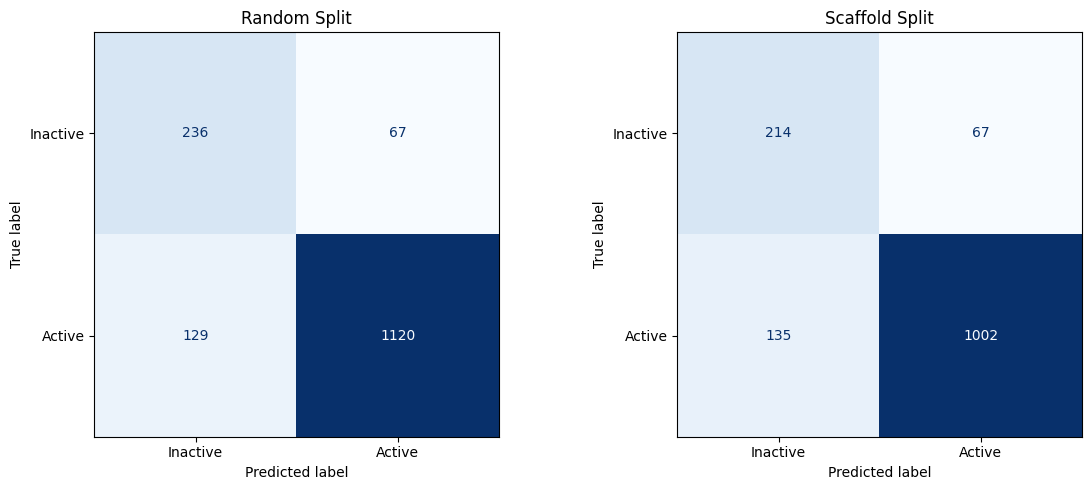

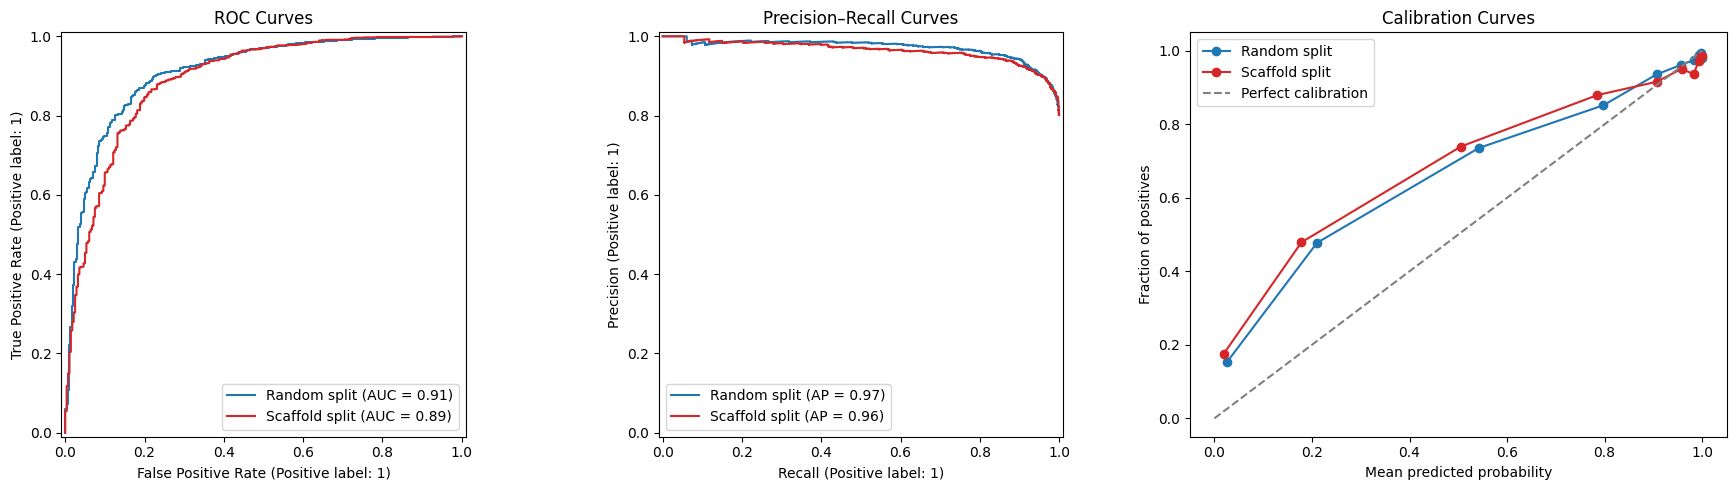

--- mediAI Day 03: Error and Calibration Audit ---

RANDOM SPLIT
error_type
Correct           1356
False Negative     129
False Positive      67
Name: count, dtype: int64
False positives: 67
False negatives: 129

SCAFFOLD SPLIT
error_type
Correct           1216
False Negative     135
False Positive      67
Name: count, dtype: int64
False positives: 67
False negatives: 135

Saved: day03_logistic_confusion_matrices.png
Saved: day03_logistic_evaluation_curves.png
Saved: day03_scaffold_split_error_analysis.csv


In [13]:
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.calibration import calibration_curve

def add_error_analysis(prediction_df):
    result = prediction_df.copy()

    result["error_type"] = np.select(
        [
            (result["activity_label"] == 0) &
            (result["predicted_label_at_0_5"] == 1),

            (result["activity_label"] == 1) &
            (result["predicted_label_at_0_5"] == 0),
        ],
        [
            "False Positive",
            "False Negative",
        ],
        default="Correct"
    )

    result["prediction_confidence"] = np.where(
        result["predicted_label_at_0_5"] == 1,
        result["predicted_probability_active"],
        1 - result["predicted_probability_active"]
    )

    return result


# Add error labels
random_error_df = add_error_analysis(random_predictions)
scaffold_error_df = add_error_analysis(scaffold_predictions)

# Save the harder scaffold-split errors separately
scaffold_error_file = "day03_scaffold_split_error_analysis.csv"

scaffold_error_df.sort_values(
    ["error_type", "prediction_confidence"],
    ascending=[True, False]
).to_csv(
    scaffold_error_file,
    index=False
)

# -------------------------------------------------------
# Plot 1: Confusion matrices
# -------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, prediction_df, title in zip(
    axes,
    [random_error_df, scaffold_error_df],
    ["Random Split", "Scaffold Split"]
):
    cm = confusion_matrix(
        prediction_df["activity_label"],
        prediction_df["predicted_label_at_0_5"],
        labels=[0, 1]
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Inactive", "Active"]
    )

    display.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(title)

plt.tight_layout()

confusion_file = "day03_logistic_confusion_matrices.png"
plt.savefig(
    confusion_file,
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# -------------------------------------------------------
# Plot 2: ROC, PR and calibration curves
# -------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for prediction_df, label, color in [
    (random_error_df, "Random split", "#1f77b4"),
    (scaffold_error_df, "Scaffold split", "#d62728"),
]:
    y_true = prediction_df["activity_label"]
    y_prob = prediction_df["predicted_probability_active"]

    RocCurveDisplay.from_predictions(
        y_true,
        y_prob,
        name=label,
        color=color,
        ax=axes[0]
    )

    PrecisionRecallDisplay.from_predictions(
        y_true,
        y_prob,
        name=label,
        color=color,
        ax=axes[1]
    )

    fraction_positive, mean_predicted = calibration_curve(
        y_true,
        y_prob,
        n_bins=10,
        strategy="quantile"
    )

    axes[2].plot(
        mean_predicted,
        fraction_positive,
        marker="o",
        label=label,
        color=color
    )

axes[0].set_title("ROC Curves")
axes[1].set_title("Precision–Recall Curves")

axes[2].plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Perfect calibration"
)

axes[2].set_title("Calibration Curves")
axes[2].set_xlabel("Mean predicted probability")
axes[2].set_ylabel("Fraction of positives")
axes[2].legend()

for ax in axes[:2]:
    ax.legend()

plt.tight_layout()

curve_file = "day03_logistic_evaluation_curves.png"
plt.savefig(
    curve_file,
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# -------------------------------------------------------
# Print error audit
# -------------------------------------------------------

print("--- mediAI Day 03: Error and Calibration Audit ---")

for name, error_df in [
    ("Random split", random_error_df),
    ("Scaffold split", scaffold_error_df),
]:
    print(f"\n{name.upper()}")
    print(error_df["error_type"].value_counts())

    false_positive_count = (
        error_df["error_type"] == "False Positive"
    ).sum()

    false_negative_count = (
        error_df["error_type"] == "False Negative"
    ).sum()

    print("False positives:", false_positive_count)
    print("False negatives:", false_negative_count)

print(f"\nSaved: {confusion_file}")
print(f"Saved: {curve_file}")
print(f"Saved: {scaffold_error_file}")

In [14]:
from pathlib import Path
from datetime import date

# Extract baseline rows safely
random_result = metrics_df[
    metrics_df["experiment"] == "random_split"
].iloc[0]

scaffold_result = metrics_df[
    metrics_df["experiment"] == "scaffold_split"
].iloc[0]

random_fp = (
    random_error_df["error_type"] == "False Positive"
).sum()

random_fn = (
    random_error_df["error_type"] == "False Negative"
).sum()

scaffold_fp = (
    scaffold_error_df["error_type"] == "False Positive"
).sum()

scaffold_fn = (
    scaffold_error_df["error_type"] == "False Negative"
).sum()

data_card = f"""# mediAI Day 03 — EGFR Bioactivity Classification Data Card

## Project question

Can a transparent Morgan-fingerprint Logistic Regression baseline classify
curated ChEMBL human EGFR activity labels, and how does performance change
between random and scaffold-based evaluation?

## Data source

- Source: ChEMBL public REST API
- Target: Human Epidermal Growth Factor Receptor (EGFR)
- Target ChEMBL ID: CHEMBL203
- Dataset audit date: {date.today().isoformat()}
- Measurement: standardized IC50
- Units: nM
- Relation: exact equals sign only
- Assay type: Binding assay
- Primary confidence rule: confidence score 9
- Primary relationship rule: direct target relationship

## Curation decisions

- Raw EGFR IC50 records: {len(raw_df):,}
- Conservative candidate records: {len(candidate_df):,}
- High-confidence direct records: {len(primary_records_df):,}
- High-confidence unique molecules before label-stability filtering:
  {primary_molecule_df["molecule_chembl_id"].nunique():,}
- Molecules removed because repeat measurements crossed the activity threshold:
  {primary_molecule_df["crosses_activity_threshold"].sum():,}
- Final unique standardized structures: {len(primary_model_df):,}

## Label definition

- Active: median pChEMBL >= 6.0
- Inactive: median pChEMBL < 6.0
- Equivalent potency threshold: IC50 <= 1 micromolar
- Duplicate measurement aggregation: median pChEMBL per molecule

## Final class balance

- Active: {(primary_model_df["activity_label"] == 1).sum():,}
- Inactive: {(primary_model_df["activity_label"] == 0).sum():,}

## Molecular representation

- Fingerprint: Morgan fingerprint
- Radius: {FP_RADIUS}
- Fingerprint size: {FP_SIZE} bits
- Unique Murcko scaffolds: {model_df["murcko_scaffold"].nunique():,}

## Baseline model

- Model: Logistic Regression
- Class weighting: balanced
- Random seed: {RANDOM_SEED}
- Classification threshold: 0.50

## Random split results

- ROC-AUC: {random_result["roc_auc"]:.4f}
- PR-AUC: {random_result["pr_auc"]:.4f}
- MCC: {random_result["mcc"]:.4f}
- Balanced accuracy: {random_result["balanced_accuracy"]:.4f}
- Brier score: {random_result["brier_score"]:.4f}
- False positives: {random_fp}
- False negatives: {random_fn}

## Scaffold split results

- ROC-AUC: {scaffold_result["roc_auc"]:.4f}
- PR-AUC: {scaffold_result["pr_auc"]:.4f}
- MCC: {scaffold_result["mcc"]:.4f}
- Balanced accuracy: {scaffold_result["balanced_accuracy"]:.4f}
- Brier score: {scaffold_result["brier_score"]:.4f}
- False positives: {scaffold_fp}
- False negatives: {scaffold_fn}

## Limitations

1. This is internal validation on one public ChEMBL-derived dataset.
2. A scaffold split is stronger than a random split, but it is not external validation.
3. The active/inactive label depends on the predeclared pChEMBL 6.0 threshold.
4. ChEMBL measurements can vary across experiments and laboratories.
5. This model does not predict clinical safety, patient benefit, efficacy, dosage,
   pharmacokinetics, toxicity, or regulatory approval.
6. The results are for computational research and hypothesis generation only.

## Next steps

1. Compare a second classical baseline.
2. Perform threshold and calibration sensitivity analysis.
3. Inspect scaffold-split false positives and false negatives.
4. Prepare a reproducible GitHub report and video evidence.
"""

data_card_file = "day03_egfr_data_card.md"

Path(data_card_file).write_text(
    data_card,
    encoding="utf-8"
)

print(data_card)

print(f"\nSaved: {data_card_file}")

# mediAI Day 03 — EGFR Bioactivity Classification Data Card

## Project question

Can a transparent Morgan-fingerprint Logistic Regression baseline classify
curated ChEMBL human EGFR activity labels, and how does performance change
between random and scaffold-based evaluation?

## Data source

- Source: ChEMBL public REST API
- Target: Human Epidermal Growth Factor Receptor (EGFR)
- Target ChEMBL ID: CHEMBL203
- Dataset audit date: 2026-10-14
- Measurement: standardized IC50
- Units: nM
- Relation: exact equals sign only
- Assay type: Binding assay
- Primary confidence rule: confidence score 9
- Primary relationship rule: direct target relationship

## Curation decisions

- Raw EGFR IC50 records: 19,646
- Conservative candidate records: 16,084
- High-confidence direct records: 12,070
- High-confidence unique molecules before label-stability filtering:
  8,106
- Molecules removed because repeat measurements crossed the activity threshold:
  320
- Final unique standardized structures: 7,

In [15]:
from google.colab import drive

drive.mount("/content/drive")

ValueError: mount failed

In [16]:
# Clear any stale Drive mount safely
!umount /content/drive 2>/dev/null || true

# Kill only stale DriveFS processes
!ps -ef | awk '/[d]rivefs/ {print $2}' | xargs -r kill -9

# Remove stale mount folder
!rm -rf /content/drive

print("Stale DriveFS mount cleared.")

Stale DriveFS mount cleared.


In [17]:
from google.colab import drive

drive.mount(
    "/content/drive",
    force_remount=True
)

Mounted at /content/drive


In [18]:
from pathlib import Path
from datetime import datetime
import shutil

archive_dir = Path(
    "/content/drive/MyDrive/mediAI/"
    "03_chembl_egfr_dataset_audit"
)

archive_dir.mkdir(
    parents=True,
    exist_ok=True
)

files_to_archive = [
    # Raw data + initial audit
    "day03_egfr_raw_ic50_activity.csv",
    "day03_egfr_candidate_records_before_aggregation.csv",
    "day03_egfr_molecule_level_audit.csv",
    "day03_egfr_molecule_level_median_all.csv",
    "day03_egfr_stable_label_candidates.csv",

    # RDKit + assay-confidence audit
    "day03_egfr_rdkit_structure_audit.csv",
    "day03_egfr_model_ready_candidate.csv",
    "day03_egfr_assay_metadata.csv",
    "day03_egfr_candidate_records_with_assay_metadata.csv",

    # Primary curated dataset
    "day03_egfr_primary_high_confidence_records.csv",
    "day03_egfr_primary_model_candidate.csv",

    # Fingerprints and reproducible splits
    "day03_egfr_morgan_fingerprints.npz",
    "day03_egfr_split_assignments.csv",

    # Baseline results + prediction/error files
    "day03_logistic_baseline_metrics.csv",
    "day03_random_split_test_predictions.csv",
    "day03_scaffold_split_test_predictions.csv",
    "day03_scaffold_split_error_analysis.csv",

    # Figures + scientific data card
    "day03_logistic_confusion_matrices.png",
    "day03_logistic_evaluation_curves.png",
    "day03_egfr_data_card.md",
]

saved_files = []
missing_files = []

for filename in files_to_archive:
    source = Path(filename)

    if source.exists():
        shutil.copy2(
            source,
            archive_dir / source.name
        )
        saved_files.append(source.name)
    else:
        missing_files.append(filename)

manifest_file = archive_dir / "day03_archive_manifest.txt"

manifest_text = (
    "mediAI Day 03 Archive Manifest\n"
    f"Archived at: {datetime.now().isoformat()}\n"
    f"Folder: {archive_dir}\n\n"
    "Saved files:\n"
    + "\n".join(f"- {name}" for name in saved_files)
    + "\n\nMissing files:\n"
    + (
        "\n".join(f"- {name}" for name in missing_files)
        if missing_files
        else "None"
    )
)

manifest_file.write_text(
    manifest_text,
    encoding="utf-8"
)

print("--- mediAI Day 03 Archive Complete ---")
print("Drive folder:", archive_dir)
print("Files copied:", len(saved_files))
print("Missing files:", len(missing_files))
print("\nManifest saved:", manifest_file)

--- mediAI Day 03 Archive Complete ---
Drive folder: /content/drive/MyDrive/mediAI/03_chembl_egfr_dataset_audit
Files copied: 20
Missing files: 0

Manifest saved: /content/drive/MyDrive/mediAI/03_chembl_egfr_dataset_audit/day03_archive_manifest.txt


In [19]:
from pathlib import Path
import shutil

archive_dir = Path(
    "/content/drive/MyDrive/mediAI/"
    "03_chembl_egfr_dataset_audit"
)

github_publish_dir = archive_dir / "github_publish_day03"

github_publish_dir.mkdir(
    parents=True,
    exist_ok=True
)

github_public_files = [
    "day03_egfr_data_card.md",
    "day03_logistic_baseline_metrics.csv",
    "day03_logistic_confusion_matrices.png",
    "day03_logistic_evaluation_curves.png",
    "day03_egfr_split_assignments.csv",
    "day03_scaffold_split_error_analysis.csv",
]

copied_files = []
missing_files = []

for filename in github_public_files:
    source = archive_dir / filename

    if source.exists():
        shutil.copy2(
            source,
            github_publish_dir / filename
        )
        copied_files.append(filename)
    else:
        missing_files.append(filename)

print("--- mediAI Day 03 GitHub Publish Folder ---")
print("Folder:", github_publish_dir)
print("Files copied:", len(copied_files))
print("Missing files:", len(missing_files))

print("\nReady for GitHub:")
for file in copied_files:
    print("-", file)

--- mediAI Day 03 GitHub Publish Folder ---
Folder: /content/drive/MyDrive/mediAI/03_chembl_egfr_dataset_audit/github_publish_day03
Files copied: 6
Missing files: 0

Ready for GitHub:
- day03_egfr_data_card.md
- day03_logistic_baseline_metrics.csv
- day03_logistic_confusion_matrices.png
- day03_logistic_evaluation_curves.png
- day03_egfr_split_assignments.csv
- day03_scaffold_split_error_analysis.csv


In [20]:
import shutil
from google.colab import files

zip_file = shutil.make_archive(
    "/content/mediAI_day03_github_publish",
    "zip",
    github_publish_dir
)

print("Created:", zip_file)

files.download(zip_file)

Created: /content/mediAI_day03_github_publish.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>